## Import the required libraries

In [2]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
import seaborn as sns

## Load the dataset

In [3]:
df = pd.read_csv("Stravl_Travel_Preference_Data.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (80301, 38)


,id,form_a,form_b,form_c,form_f,form_g,form_h,form_i,form_j,form_k,...,Rec_0,Rec_1,Rec_2,Rec_3,Rec_4,Rec_5,Rec_6,Rec_7,Rec_8,Rec_9
0,22871c2cb8ee11ec9a19fefb5d5b7ead,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],['2'],...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
1,89b7022ab8f011ec9a19fefb5d5b7ead,"['0', '1']",['3'],['2'],"['0', '3', '4', '5', '6', '7']","['0', '1', '2', '4']",['1'],['1'],['1'],['1'],...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
2,c64f6c36b8f011ec9a19fefb5d5b7ead,['1'],['1'],['2'],"['0', '1', '3', '4', '7']","['0', '2', '4', '7']",['1'],['1'],['1'],['0'],...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
3,1eb6079ab8f111ec9a19fefb5d5b7ead,['1'],['1'],['2'],['7'],['4'],['1'],['2'],['1'],['1'],...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
4,285e9852b8f111ec9a19fefb5d5b7ead,['1'],['0'],['1'],['2'],"['2', '3', '4']",['0'],['1'],['0'],['0'],...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1


## Check the dataset structure

In [4]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Columns:
['id', 'form_a', 'form_b', 'form_c', 'form_f', 'form_g', 'form_h', 'form_i', 'form_j', 'form_k', 'form_r', 'form_rr', 'yes_swipes', 'no_swipes', 'maybe_swipes', 'Model', 'Retrieval', 'DynaMatch', 'Rating_0', 'Rating_1', 'Rating_2', 'Rating_3', 'Rating_4', 'Rating_5', 'Rating_6', 'Rating_7', 'Rating_8', 'Rating_9', 'Rec_0', 'Rec_1', 'Rec_2', 'Rec_3', 'Rec_4', 'Rec_5', 'Rec_6', 'Rec_7', 'Rec_8', 'Rec_9']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 80301 entries, 0 to 80300
Data columns (total 38 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            80301 non-null  str    
 1   form_a        80300 non-null  str    
 2   form_b        80298 non-null  str    
 3   form_c        80298 non-null  str    
 4   form_f        79844 non-null  str    
 5   form_g        79007 non-null  str    
 6   form_h        80300 non-null  str    
 7   form_i        80299 non-null  str    
 8   form_j        80299 non-null  

## Check missing values

In [5]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print(missing_values.sort_values(ascending=False))

form_rr     67344
form_r      62677
Rec_5       15433
Rec_9       15433
Rec_8       15433
Rec_7       15433
Rec_6       15433
Rating_6    15425
Rating_7    15425
Rating_5    15425
Rating_8    15425
Rating_9    15425
Rec_2        4689
Rec_4        4689
Rec_3        4689
Rec_1        4688
Rec_0        4688
Rating_1     4682
Rating_0     4682
Rating_2     4682
Rating_3     4682
Rating_4     4682
form_g       1294
form_f        457
form_b          3
form_c          3
form_i          2
form_k          2
form_j          2
form_a          1
form_h          1
dtype: int64


## Define the preference fields

In [6]:
preference_cols = [
    'form_a',
    'form_b',
    'form_c',
    'form_f',
    'form_g',
    'form_h',
    'form_i',
    'form_j',
    'form_r',
    'form_rr'
]

print("Preference columns:", preference_cols)

Preference columns: ['form_a', 'form_b', 'form_c', 'form_f', 'form_g', 'form_h', 'form_i', 'form_j', 'form_r', 'form_rr']


## Convert the swipe lists into Python lists

In [7]:
def parse_swipes(value):
    if pd.isna(value):
        return []

    return ast.literal_eval(value)


df['yes_list'] = df['yes_swipes'].apply(parse_swipes)
df['no_list'] = df['no_swipes'].apply(parse_swipes)
df['maybe_list'] = df['maybe_swipes'].apply(parse_swipes)

print(df[['yes_list', 'no_list', 'maybe_list']].head())

                                         yes_list  \
0  [837, 779, 1315, 773, 621, 799, 794, 172, 190]   
1                                      [246, 579]   
2                                [526, 661, 1054]   
3             [305, 216, 142, 435, 65, 1202, 853]   
4                [1197, 359, 1428, 725, 1115, 42]   

                                             no_list maybe_list  
0  [1256, 855, 1259, 551, 55, 257, 648, 234, 209,...         []  
1          [126, 945, 865, 330, 1237, 1264, 824, 87]         []  
2                [1129, 933, 1030, 1009, 1362, 1130]      [715]  
3                                   [24, 1396, 1375]         []  
4                              [1407, 305, 150, 442]         []  


## Create traveller–destination pairs

This cell performs three operations:
1. Combines all three response lists.
2. Removes repeated responses for the same traveller and destination.
3. Identifies contradictory responses, such as the same traveller marking the same destination both Yes and No.

In [8]:
pair_labels = {}
traveller_preferences = {}

for row in df.itertuples(index=False):

    traveller_id = row.id

    traveller_preferences[traveller_id] = {
        col: getattr(row, col)
        for col in preference_cols
    }

    response_lists = {
        'Yes': row.yes_list,
        'No': row.no_list,
        'Maybe': row.maybe_list
    }

    for label, destinations in response_lists.items():

        for destination in set(destinations):

            destination_id = int(destination)

            key = (traveller_id, destination_id)

            if key not in pair_labels:
                pair_labels[key] = set()

            pair_labels[key].add(label)


print("Total unique traveller-destination pairs:", len(pair_labels))

conflicting_pairs = sum(
    1 for labels in pair_labels.values()
    if len(labels) > 1
)

print("Conflicting pairs:", conflicting_pairs)

Total unique traveller-destination pairs: 815133
Conflicting pairs: 1331


## Create the final modelling dataset

In [9]:
records = []

for (traveller_id, destination_id), labels in pair_labels.items():

    if len(labels) == 1:

        record = {
            'traveller_id': traveller_id,
            'destination_id': destination_id,
            'target': next(iter(labels))
        }

        record.update(traveller_preferences[traveller_id])

        records.append(record)


model_df = pd.DataFrame(records)

print("Modelling Dataset Shape:", model_df.shape)

model_df.head()

Modelling Dataset Shape: (813802, 13)


,traveller_id,destination_id,target,form_a,form_b,form_c,form_f,form_g,form_h,form_i,form_j,form_r,form_rr
0,22871c2cb8ee11ec9a19fefb5d5b7ead,1315,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
1,22871c2cb8ee11ec9a19fefb5d5b7ead,773,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
2,22871c2cb8ee11ec9a19fefb5d5b7ead,837,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
3,22871c2cb8ee11ec9a19fefb5d5b7ead,779,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
4,22871c2cb8ee11ec9a19fefb5d5b7ead,172,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN


## Create the final modelling dataset

In [10]:
records = []

for (traveller_id, destination_id), labels in pair_labels.items():

    if len(labels) == 1:

        record = {
            'traveller_id': traveller_id,
            'destination_id': destination_id,
            'target': next(iter(labels))
        }

        record.update(traveller_preferences[traveller_id])

        records.append(record)


model_df = pd.DataFrame(records)

print("Modelling Dataset Shape:", model_df.shape)

model_df.head()

Modelling Dataset Shape: (813802, 13)


,traveller_id,destination_id,target,form_a,form_b,form_c,form_f,form_g,form_h,form_i,form_j,form_r,form_rr
0,22871c2cb8ee11ec9a19fefb5d5b7ead,1315,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
1,22871c2cb8ee11ec9a19fefb5d5b7ead,773,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
2,22871c2cb8ee11ec9a19fefb5d5b7ead,837,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
3,22871c2cb8ee11ec9a19fefb5d5b7ead,779,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
4,22871c2cb8ee11ec9a19fefb5d5b7ead,172,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN


## Create the final modelling dataset

In [11]:
records = []

for (traveller_id, destination_id), labels in pair_labels.items():

    if len(labels) == 1:

        record = {
            'traveller_id': traveller_id,
            'destination_id': destination_id,
            'target': next(iter(labels))
        }

        record.update(traveller_preferences[traveller_id])

        records.append(record)


model_df = pd.DataFrame(records)

print("Modelling Dataset Shape:", model_df.shape)

model_df.head()

Modelling Dataset Shape: (813802, 13)


,traveller_id,destination_id,target,form_a,form_b,form_c,form_f,form_g,form_h,form_i,form_j,form_r,form_rr
0,22871c2cb8ee11ec9a19fefb5d5b7ead,1315,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
1,22871c2cb8ee11ec9a19fefb5d5b7ead,773,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
2,22871c2cb8ee11ec9a19fefb5d5b7ead,837,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
3,22871c2cb8ee11ec9a19fefb5d5b7ead,779,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
4,22871c2cb8ee11ec9a19fefb5d5b7ead,172,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN


## Check the target distribution

In [12]:
print("Target Distribution:")
print(model_df['target'].value_counts())

print("\nTarget Distribution in Percentage:")
print(
    model_df['target']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target Distribution:
target
No       498184
Yes      288756
Maybe     26862
Name: count, dtype: int64

Target Distribution in Percentage:
target
No       61.22
Yes      35.48
Maybe     3.30
Name: proportion, dtype: float64


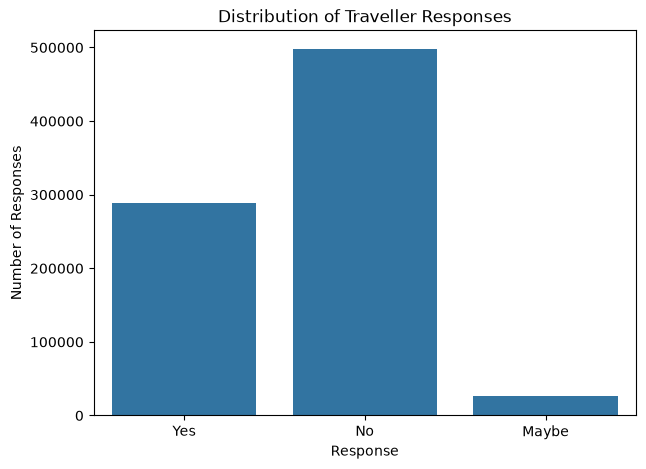

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=model_df,
    x='target',
    order=['Yes', 'No', 'Maybe']
)

plt.title("Distribution of Traveller Responses")
plt.xlabel("Response")
plt.ylabel("Number of Responses")
plt.show()

## Examine missing values in the modelling dataset

In [14]:
missing = model_df[preference_cols].isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Values': missing,
    'Missing Percentage': (
        missing / len(model_df) * 100
    ).round(2)
})

print(missing_summary)

         Missing Values  Missing Percentage
form_a               10                0.00
form_b               20                0.00
form_c               30                0.00
form_f             3790                0.47
form_g            10849                1.33
form_h               10                0.00
form_i               20                0.00
form_j               20                0.00
form_r           681028               83.68
form_rr          715386               87.91


## Create a separate preprocessing copy

In [15]:
model_df_clean = model_df.copy()

selected_features = [
    'form_a', 'form_b', 'form_c',
    'form_f', 'form_g', 'form_h',
    'form_i', 'form_j'
]

print("Original shape:", model_df.shape)
print("Working copy shape:", model_df_clean.shape)

Original shape: (813802, 13)
Working copy shape: (813802, 13)


## Handle missing preference values (removed form_r and form_rr)

In [16]:
for col in selected_features:

    # Preserve information about missing values
    model_df_clean[col + '_missing'] = (
        model_df_clean[col].isnull().astype(int)
    )

    # Represent missing selections as empty lists
    model_df_clean[col] = model_df_clean[col].fillna("[]")

print("Remaining missing values:")

print(model_df_clean[selected_features].isnull().sum())

Remaining missing values:
form_a    0
form_b    0
form_c    0
form_f    0
form_g    0
form_h    0
form_i    0
form_j    0
dtype: int64


## Verify the cleaning

In [17]:
print("Dataset Shape:", model_df_clean.shape)

print("\nMissing values:")
print(model_df_clean[selected_features].isnull().sum())

print("\nSample records:")
display(model_df_clean.head())

Dataset Shape: (813802, 21)

Missing values:
form_a    0
form_b    0
form_c    0
form_f    0
form_g    0
form_h    0
form_i    0
form_j    0
dtype: int64

Sample records:


,traveller_id,destination_id,target,form_a,form_b,form_c,form_f,form_g,form_h,form_i,...,form_r,form_rr,form_a_missing,form_b_missing,form_c_missing,form_f_missing,form_g_missing,form_h_missing,form_i_missing,form_j_missing
0,22871c2cb8ee11ec9a19fefb5d5b7ead,1315,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],...,NaN,NaN,0,0,0,0,0,0,0,0
1,22871c2cb8ee11ec9a19fefb5d5b7ead,773,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],...,NaN,NaN,0,0,0,0,0,0,0,0
2,22871c2cb8ee11ec9a19fefb5d5b7ead,837,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],...,NaN,NaN,0,0,0,0,0,0,0,0
3,22871c2cb8ee11ec9a19fefb5d5b7ead,779,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],...,NaN,NaN,0,0,0,0,0,0,0,0
4,22871c2cb8ee11ec9a19fefb5d5b7ead,172,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],...,NaN,NaN,0,0,0,0,0,0,0,0


## Examine unique preference categories

In [18]:
for col in selected_features:

    categories = set()

    for value in model_df_clean[col]:

        if value != "[]":
            categories.update(ast.literal_eval(value))

    print(f"\n{col}")
    print("Categories:", sorted(categories))
    print("Number of categories:", len(categories))


form_a
Categories: ['0', '1', '2', '3']
Number of categories: 4

form_b
Categories: ['0', '1', '2', '3']
Number of categories: 4

form_c
Categories: ['0', '1', '2', '3']
Number of categories: 4

form_f
Categories: ['0', '1', '2', '3', '4', '5', '6', '7']
Number of categories: 8

form_g
Categories: ['0', '1', '2', '3', '4', '5', '6', '7']
Number of categories: 8

form_h
Categories: ['0', '1', '2']
Number of categories: 3

form_i
Categories: ['0', '1', '2']
Number of categories: 3

form_j
Categories: ['0', '1', '2']
Number of categories: 3


## validate single-selection columns

In [19]:
single_choice_cols = [
    'form_b',
    'form_c',
    'form_h',
    'form_i',
    'form_j'
]

for col in single_choice_cols:
    lengths = model_df_clean[col].apply(
        lambda x: len(ast.literal_eval(x))
    )

    print(f"\n{col}")
    print(lengths.value_counts().sort_index())


form_b
form_b
0        20
1    681008
4    132774
Name: count, dtype: int64

form_c
form_c
0        30
1    813772
Name: count, dtype: int64

form_h
form_h
0        10
1    813792
Name: count, dtype: int64

form_i
form_i
0        20
1    813782
Name: count, dtype: int64

form_j
form_j
0        20
1    681018
3    132764
Name: count, dtype: int64


## Inspect the unexpected multiple answers

In [20]:
for col in ['form_b', 'form_c', 'form_h', 'form_i', 'form_j']:

    print("\n" + "=" * 50)
    print("COLUMN:", col)

    parsed = df[col].apply(parse_swipes)
    lengths = parsed.apply(len)

    print("\nList length distribution:")
    print(lengths.value_counts().sort_index())

    unusual = df.loc[lengths > 1, ['id', col]]

    if len(unusual) > 0:
        print("\nExamples with multiple answers:")
        print(unusual.head(10).to_string(index=False))


COLUMN: form_b

List length distribution:
form_b
0        3
1    62673
4    17625
Name: count, dtype: int64

Examples with multiple answers:
                              id               form_b
738932fcd28011ed86bd1238d4348226 ['0', '1', '2', '3']
a0c91202d28311eda45116bdf5dc994c ['0', '1', '2', '3']
96aa1a02ba1211edad17acde48001122 ['0', '1', '2', '3']
d62c6ac0ba1011eda218d5b311908a22 ['0', '1', '2', '3']
0b897532ba1211ed9de0d5b311908a22 ['0', '1', '2', '3']
b68f5a24d28311edadc00e96bc2eb5a0 ['0', '1', '2', '3']
f3a11bd2d28311edadc00e96bc2eb5a0 ['0', '1', '2', '3']
f3567550d28311edb5a9f6957d14b1a7 ['0', '1', '2', '3']
09b0ff2ad28211eda45116bdf5dc994c ['0', '1', '2', '3']
5c19047ed28211eda45116bdf5dc994c ['0', '1', '2', '3']

COLUMN: form_c

List length distribution:
form_c
0        3
1    80298
Name: count, dtype: int64

COLUMN: form_h

List length distribution:
form_h
0        1
1    80300
Name: count, dtype: int64

COLUMN: form_i

List length distribution:
form_i
0        2
1    80

## inspect the unusual patterns in all five columns

In [21]:
for col in ['form_b', 'form_c', 'form_h', 'form_i', 'form_j']:

    parsed = df[col].apply(parse_swipes)

    unusual = parsed[parsed.apply(len) > 1]

    print("\n" + "=" * 45)
    print("COLUMN:", col)
    print("Rows with multiple answers:", len(unusual))

    if len(unusual) > 0:
        patterns = unusual.apply(lambda x: tuple(x)).value_counts()

        print("\nMost common multiple-answer patterns:")
        print(patterns.head(10))


COLUMN: form_b
Rows with multiple answers: 17625

Most common multiple-answer patterns:
form_b
(0, 1, 2, 3)    17625
Name: count, dtype: int64

COLUMN: form_c
Rows with multiple answers: 0

COLUMN: form_h
Rows with multiple answers: 0

COLUMN: form_i
Rows with multiple answers: 0

COLUMN: form_j
Rows with multiple answers: 17623

Most common multiple-answer patterns:
form_j
(0, 1, 2)    17623
Name: count, dtype: int64


## check whether the two patterns occur for the same travellers

In [22]:
# Identify travellers with all options selected
form_b_all = df['form_b'].apply(
    lambda x: set(parse_swipes(x)) == {'0', '1', '2', '3'}
)

form_j_all = df['form_j'].apply(
    lambda x: set(parse_swipes(x)) == {'0', '1', '2'}
)

print("Travellers with all budget options:", form_b_all.sum())

print("Travellers with all popularity options:", form_j_all.sum())

print("Travellers with both patterns:", (form_b_all & form_j_all).sum())

print("Travellers with only budget pattern:", (form_b_all & ~form_j_all).sum())

print("Travellers with only popularity pattern:", (~form_b_all & form_j_all).sum())

Travellers with all budget options: 17625
Travellers with all popularity options: 17623
Travellers with both patterns: 17623
Travellers with only budget pattern: 2
Travellers with only popularity pattern: 0


## count affected records in our modelling dataset

In [23]:
# Get IDs of travellers with ambiguous preference responses
budget_all_ids = set(df.loc[form_b_all, 'id'])

popularity_all_ids = set(df.loc[form_j_all, 'id'])

# Count affected rows in the modelling dataset
budget_rows = model_df_clean['traveller_id'].isin(budget_all_ids)

popularity_rows = model_df_clean['traveller_id'].isin(popularity_all_ids)

either_rows = budget_rows | popularity_rows

print("Unique travellers with ambiguous budget:", len(budget_all_ids))

print("Unique travellers with ambiguous popularity:", len(popularity_all_ids))

print("Modelling rows affected by budget:", budget_rows.sum())

print("Modelling rows affected by popularity:", popularity_rows.sum())

print("Total unique modelling rows affected:", either_rows.sum())

Unique travellers with ambiguous budget: 17625
Unique travellers with ambiguous popularity: 17623
Modelling rows affected by budget: 132774
Modelling rows affected by popularity: 132764
Total unique modelling rows affected: 132774


## Handle the ambiguous responses

In [24]:
# Identify affected modelling rows
budget_mask = model_df_clean['traveller_id'].isin(budget_all_ids)
popularity_mask = model_df_clean['traveller_id'].isin(popularity_all_ids)

# Keep separate indicators to record why values are unavailable
model_df_clean['form_b_ambiguous'] = budget_mask.astype(int)
model_df_clean['form_j_ambiguous'] = popularity_mask.astype(int)

# Replace ambiguous answers with empty lists
model_df_clean.loc[budget_mask, 'form_b'] = "[]"
model_df_clean.loc[popularity_mask, 'form_j'] = "[]"

# Update missing-value indicators
model_df_clean.loc[budget_mask, 'form_b_missing'] = 1
model_df_clean.loc[popularity_mask, 'form_j_missing'] = 1

print("Ambiguous budget rows:", model_df_clean['form_b_ambiguous'].sum())
print("Ambiguous popularity rows:", model_df_clean['form_j_ambiguous'].sum())

print("\nRemaining ambiguous budget values:",
      (model_df_clean['form_b'] == "['0', '1', '2', '3']").sum())

print("Remaining ambiguous popularity values:",
      (model_df_clean['form_j'] == "['0', '1', '2']").sum())

Ambiguous budget rows: 132774
Ambiguous popularity rows: 132764

Remaining ambiguous budget values: 0
Remaining ambiguous popularity values: 0


## Multi-hot encode multiple-selection preferences

In [25]:
# Define the available categories for multiple-selection columns
multi_select_categories = {
    'form_a': ['0', '1', '2', '3'],
    'form_f': ['0', '1', '2', '3', '4', '5', '6', '7'],
    'form_g': ['0', '1', '2', '3', '4', '5', '6', '7']
}

# Create a separate DataFrame for encoded features
encoded_features = pd.DataFrame(index=model_df_clean.index)

# Perform multi-hot encoding
for col, categories in multi_select_categories.items():

    parsed_values = model_df_clean[col].apply(ast.literal_eval)

    for category in categories:
        encoded_features[f'{col}_{category}'] = (
            parsed_values.apply(lambda values: int(category in values))
        )

# Display the results
print("Encoded feature shape:", encoded_features.shape)

print("\nFirst five rows:")
print(encoded_features.head())

Encoded feature shape: (813802, 20)

First five rows:
   form_a_0  form_a_1  form_a_2  form_a_3  form_f_0  form_f_1  form_f_2  \
0         1         1         0         0         1         1         1   
1         1         1         0         0         1         1         1   
2         1         1         0         0         1         1         1   
3         1         1         0         0         1         1         1   
4         1         1         0         0         1         1         1   

   form_f_3  form_f_4  form_f_5  form_f_6  form_f_7  form_g_0  form_g_1  \
0         0         0         0         0         1         1         0   
1         0         0         0         0         1         1         0   
2         0         0         0         0         1         1         0   
3         0         0         0         0         1         1         0   
4         0         0         0         0         1         1         0   

   form_g_2  form_g_3  form_g_4  form_g_5  f

## One-hot encode single-selection preferences

In [26]:
# Define categories for single-selection preferences
single_select_categories = {
    'form_b': ['0', '1', '2', '3'],
    'form_c': ['0', '1', '2', '3'],
    'form_h': ['0', '1', '2'],
    'form_i': ['0', '1', '2'],
    'form_j': ['0', '1', '2']
}

# Perform one-hot encoding
for col, categories in single_select_categories.items():

    parsed_values = model_df_clean[col].apply(ast.literal_eval)

    for category in categories:
        encoded_features[f'{col}_{category}'] = (
            parsed_values.apply(lambda values: int(category in values))
        )

# Display results
print("Total encoded feature shape:", encoded_features.shape)

print("\nAll encoded feature columns:")
print(encoded_features.columns.tolist())

print("\nFirst five rows:")
print(encoded_features.head())

Total encoded feature shape: (813802, 37)

All encoded feature columns:
['form_a_0', 'form_a_1', 'form_a_2', 'form_a_3', 'form_f_0', 'form_f_1', 'form_f_2', 'form_f_3', 'form_f_4', 'form_f_5', 'form_f_6', 'form_f_7', 'form_g_0', 'form_g_1', 'form_g_2', 'form_g_3', 'form_g_4', 'form_g_5', 'form_g_6', 'form_g_7', 'form_b_0', 'form_b_1', 'form_b_2', 'form_b_3', 'form_c_0', 'form_c_1', 'form_c_2', 'form_c_3', 'form_h_0', 'form_h_1', 'form_h_2', 'form_i_0', 'form_i_1', 'form_i_2', 'form_j_0', 'form_j_1', 'form_j_2']

First five rows:
   form_a_0  form_a_1  form_a_2  form_a_3  form_f_0  form_f_1  form_f_2  \
0         1         1         0         0         1         1         1   
1         1         1         0         0         1         1         1   
2         1         1         0         0         1         1         1   
3         1         1         0         0         1         1         1   
4         1         1         0         0         1         1         1   

   form_f_3  f

## Add missing-value indicators

In [27]:
# Add missing-value indicators for all eight preference columns
for col in selected_features:
    missing_col = col + '_missing'

    encoded_features[missing_col] = (
        model_df_clean[missing_col].astype(int)
    )

# Add indicators for the ambiguous responses
encoded_features['form_b_ambiguous'] = (
    model_df_clean['form_b_ambiguous'].astype(int)
)

encoded_features['form_j_ambiguous'] = (
    model_df_clean['form_j_ambiguous'].astype(int)
)

# Check the final preference feature dataset
print("Final preference feature shape:", encoded_features.shape)

print("\nMissing-value indicators:")
print(encoded_features[[col + '_missing' for col in selected_features]].sum())

print("\nAmbiguous response indicators:")
print(encoded_features[['form_b_ambiguous', 'form_j_ambiguous']].sum())

Final preference feature shape: (813802, 47)

Missing-value indicators:
form_a_missing        10
form_b_missing    132794
form_c_missing        30
form_f_missing      3790
form_g_missing     10849
form_h_missing        10
form_i_missing        20
form_j_missing    132784
dtype: int64

Ambiguous response indicators:
form_b_ambiguous    132774
form_j_ambiguous    132764
dtype: int64


## Validate the encoded dataset

In [28]:
# Check encoded dataset dimensions
print("Dataset shape:", encoded_features.shape)

# Check for missing values
print("\nTotal missing values:")
print(encoded_features.isnull().sum().sum())

# Check for duplicate columns
print("\nDuplicate columns:")
print(encoded_features.columns[encoded_features.columns.duplicated()].tolist())

# Check that all encoded values are binary
print("\nUnique values across encoded features:")
print(sorted(pd.unique(encoded_features.to_numpy().ravel())))

# Check row alignment
print("\nIndex matches modelling dataset:",
      encoded_features.index.equals(model_df_clean.index))

Dataset shape: (813802, 47)

Total missing values:
0

Duplicate columns:
[]

Unique values across encoded features:
[np.int64(0), np.int64(1)]

Index matches modelling dataset: True


## Prepare destination features

In [29]:
# Inspect the destination mapping file

with open("destinations_id.txt", "r", encoding="utf-8") as file:

    for i in range(10):
        line = file.readline()

        if not line:
            break

        print(line.rstrip())

Butrint, Albania
Tirana, Albania
Algiers, Algeria
Oran, Algeria
Andorra la Vella, Andorra
Jolly Harbour, Antigua and Barbuda
St John's, Antigua and Barbuda
Buenos Aires, Argentina
Córdoba, Argentina
Mar del Plata, Argentina


## Load and inspect destination mappings

In [30]:
# Load destination names from the mapping file
with open("destinations_id.txt", "r", encoding="utf-8") as file:
    destination_names = [
        line.strip()
        for line in file
        if line.strip()
    ]

# Inspect the mapping
print("Total destinations:", len(destination_names))

print("\nFirst 10 destinations:")
for i, destination in enumerate(destination_names[:10]):
    print(i, ":", destination)

# Inspect destination IDs in the modelling dataset
print("\nMinimum destination ID:", model_df_clean['destination_id'].min())
print("Maximum destination ID:", model_df_clean['destination_id'].max())
print("Unique destination IDs:", model_df_clean['destination_id'].nunique())

# Check whether all IDs are valid mapping indices
valid_ids = model_df_clean['destination_id'].between(
    0, len(destination_names) - 1
)

print("\nValid destination ID rows:", valid_ids.sum())
print("Invalid destination ID rows:", (~valid_ids).sum())

Total destinations: 1486

First 10 destinations:
0 : Butrint, Albania
1 : Tirana, Albania
2 : Algiers, Algeria
3 : Oran, Algeria
4 : Andorra la Vella, Andorra
5 : Jolly Harbour, Antigua and Barbuda
6 : St John's, Antigua and Barbuda
7 : Buenos Aires, Argentina
8 : Córdoba, Argentina
9 : Mar del Plata, Argentina

Minimum destination ID: 0
Maximum destination ID: 1485
Unique destination IDs: 1452

Valid destination ID rows: 813802
Invalid destination ID rows: 0


## Extract city and country information

In [31]:
# Create a destination mapping DataFrame
destination_map = pd.DataFrame({
    'destination_id': range(len(destination_names)),
    'destination': destination_names
})

# Separate city and country
split_names = destination_map['destination'].str.rsplit(
    ',', n=1, expand=True
)

destination_map['city'] = split_names[0].str.strip()
destination_map['country'] = split_names[1].str.strip()

# Inspect the mapping
print("Destination mapping shape:", destination_map.shape)

print("\nNumber of unique cities:",
      destination_map['city'].nunique())

print("Number of unique countries:",
      destination_map['country'].nunique())

print("\nMissing city values:",
      destination_map['city'].isna().sum())

print("Missing country values:",
      destination_map['country'].isna().sum())

print("\nTop 15 countries by number of destinations:")
print(destination_map['country'].value_counts().head(15))

print("\nSample destination mapping:")
print(destination_map.head(10))

Destination mapping shape: (1486, 4)

Number of unique cities: 1481
Number of unique countries: 143

Missing city values: 0
Missing country values: 0

Top 15 countries by number of destinations:
country
United States     603
Italy              36
France             35
Germany            34
Spain              33
United Kingdom     26
Greece             25
Brazil             21
Mexico             21
China              19
Egypt              17
Canada             16
Switzerland        16
Australia          15
Austria            15
Name: count, dtype: int64

Sample destination mapping:
   destination_id                         destination              city  \
0               0                    Butrint, Albania           Butrint   
1               1                     Tirana, Albania            Tirana   
2               2                    Algiers, Algeria           Algiers   
3               3                       Oran, Algeria              Oran   
4               4           Andorra l

## Attach destination city and country to modelling records

In [32]:
# Create destination ID-to-city and ID-to-country mappings
city_mapping = destination_map.set_index('destination_id')['city']
country_mapping = destination_map.set_index('destination_id')['country']

# Attach destination information to modelling dataset
model_df_clean['destination_city'] = (
    model_df_clean['destination_id'].map(city_mapping)
)

model_df_clean['destination_country'] = (
    model_df_clean['destination_id'].map(country_mapping)
)

# Validate destination information
print("Missing city values:",
      model_df_clean['destination_city'].isna().sum())

print("Missing country values:",
      model_df_clean['destination_country'].isna().sum())

print("\nUnique destination cities:",
      model_df_clean['destination_city'].nunique())

print("Unique destination countries:",
      model_df_clean['destination_country'].nunique())

print("\nTop 15 countries by traveller-destination records:")
print(model_df_clean['destination_country'].value_counts().head(15))

print("\nSample records:")
print(
    model_df_clean[
        ['destination_id', 'destination_city', 'destination_country']
    ].head(10)
)

Missing city values: 0
Missing country values: 0

Unique destination cities: 1448
Unique destination countries: 143

Top 15 countries by traveller-destination records:
destination_country
United States     323967
Italy              26370
Germany            23165
France             22509
Spain              18711
United Kingdom     16574
Greece             16142
China              12486
Canada             12470
Mexico             12396
Brazil             11932
Croatia            10423
Australia          10383
Austria             9539
Japan               9138
Name: count, dtype: int64

Sample records:
   destination_id      destination_city   destination_country
0            1315  Lincoln City, Oregon         United States
1             773             Stockholm                Sweden
2             837                 Dubai  United Arab Emirates
3             779                Geneva           Switzerland
4             172               Popayan              Colombia
5             621     

## examine destination interaction frequency

In [33]:
# Count traveller-destination records for each destination
destination_counts = model_df_clean['destination_id'].value_counts()

print("Number of destinations with interactions:",
      len(destination_counts))

print("\nDestination interaction frequency:")
print(destination_counts.describe())

print("\nDestinations with fewer than 10 records:",
      (destination_counts < 10).sum())

print("Destinations with fewer than 50 records:",
      (destination_counts < 50).sum())

print("Destinations with at least 100 records:",
      (destination_counts >= 100).sum())

print("\nTop 15 most frequently selected destinations:")
print(destination_counts.head(15))

Number of destinations with interactions: 1452

Destination interaction frequency:
count    1452.000000
mean      560.469697
std       406.823631
min         1.000000
25%       352.000000
50%       376.000000
75%       497.000000
max      3220.000000
Name: count, dtype: float64

Destinations with fewer than 10 records: 15
Destinations with fewer than 50 records: 27
Destinations with at least 100 records: 1419

Top 15 most frequently selected destinations:
destination_id
356     3220
338     2870
821     2615
207     2565
732     2428
1481    2231
49      2229
439     2151
275     2093
212     2021
938     2016
450     1949
189     1942
474     1795
1006    1782
Name: count, dtype: int64


## verify the destination columns before encoding

In [34]:
# Check destination-related columns
destination_cols = [
    col for col in model_df_clean.columns
    if 'destination' in col.lower()
]

print("Destination-related columns:")
print(destination_cols)

print("\nFirst five destination records:")
print(model_df_clean[destination_cols].head())

print("\nMissing values in destination columns:")
print(model_df_clean[destination_cols].isnull().sum())

Destination-related columns:
['destination_id', 'destination_city', 'destination_country']

First five destination records:
   destination_id      destination_city   destination_country
0            1315  Lincoln City, Oregon         United States
1             773             Stockholm                Sweden
2             837                 Dubai  United Arab Emirates
3             779                Geneva           Switzerland
4             172               Popayan              Colombia

Missing values in destination columns:
destination_id         0
destination_city       0
destination_country    0
dtype: int64


## prepare destination features for encoding

In [35]:
# Prepare destination features

destination_features = model_df_clean[
    ['destination_id', 'destination_country']
].copy()

# Convert destination ID to categorical text
destination_features['destination_id'] = (
    destination_features['destination_id'].astype(str)
)

# Ensure country is treated as categorical text
destination_features['destination_country'] = (
    destination_features['destination_country'].astype(str)
)

print("Destination feature shape:",
      destination_features.shape)

print("\nDestination feature data types:")
print(destination_features.dtypes)

print("\nUnique destination IDs:",
      destination_features['destination_id'].nunique())

print("Unique countries:",
      destination_features['destination_country'].nunique())

print("\nFirst five rows:")
print(destination_features.head())

Destination feature shape: (813802, 2)

Destination feature data types:
destination_id         str
destination_country    str
dtype: object

Unique destination IDs: 1452
Unique countries: 143

First five rows:
  destination_id   destination_country
0           1315         United States
1            773                Sweden
2            837  United Arab Emirates
3            779           Switzerland
4            172              Colombia


## inspect the target and traveller columns

In [37]:
print("Modelling dataset columns:")
print(model_df_clean.columns.tolist())

print("\nEncoded preference feature shape:")
print(encoded_features.shape)

print("\nTarget response distribution:")
print(model_df_clean['target'].value_counts())

print("\nTarget response percentages:")
print(
    (model_df_clean['target'].value_counts(normalize=True) * 100)
    .round(2)
)

Modelling dataset columns:
['traveller_id', 'destination_id', 'target', 'form_a', 'form_b', 'form_c', 'form_f', 'form_g', 'form_h', 'form_i', 'form_j', 'form_r', 'form_rr', 'form_a_missing', 'form_b_missing', 'form_c_missing', 'form_f_missing', 'form_g_missing', 'form_h_missing', 'form_i_missing', 'form_j_missing', 'form_b_ambiguous', 'form_j_ambiguous', 'destination_city', 'destination_country']

Encoded preference feature shape:
(813802, 47)

Target response distribution:
target
No       498184
Yes      288756
Maybe     26862
Name: count, dtype: int64

Target response percentages:
target
No       61.22
Yes      35.48
Maybe     3.30
Name: proportion, dtype: float64


## Encode destination features.

In [39]:
from sklearn.preprocessing import OneHotEncoder

# Create One-Hot Encoder
destination_encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=True
)

# Encode destination ID and country
destination_encoded = destination_encoder.fit_transform(
    destination_features[
        ['destination_id', 'destination_country']
    ]
)

# Display the results
print("Original destination feature shape:")
print(destination_features.shape)

print("\nEncoded destination feature shape:")
print(destination_encoded.shape)

print("\nNumber of encoded destination categories:")
print(destination_encoded.shape[1])

print("\nEncoder completed successfully!")

Original destination feature shape:
(813802, 2)

Encoded destination feature shape:
(813802, 1595)

Number of encoded destination categories:
1595

Encoder completed successfully!


## Prepare X and y
X: Traveller preferences and destination information.
y: The target response (Yes, No, or Maybe).

In [38]:
# Combine encoded traveller preferences
# with destination information

X = pd.concat(
    [encoded_features, destination_features],
    axis=1
)

# Target variable
y = model_df_clean['target'].copy()

# Traveller IDs for group-based splitting
groups = model_df_clean['traveller_id'].copy()

# Verify the prepared data
print("Input feature shape:", X.shape)
print("Target shape:", y.shape)
print("Number of unique travellers:", groups.nunique())

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

print("\nFirst five input rows:")
print(X.head())

Input feature shape: (813802, 49)
Target shape: (813802,)
Number of unique travellers: 61130

Missing values in X: 0
Missing values in y: 0

First five input rows:
   form_a_0  form_a_1  form_a_2  form_a_3  form_f_0  form_f_1  form_f_2  \
0         1         1         0         0         1         1         1   
1         1         1         0         0         1         1         1   
2         1         1         0         0         1         1         1   
3         1         1         0         0         1         1         1   
4         1         1         0         0         1         1         1   

   form_f_3  form_f_4  form_f_5  ...  form_c_missing  form_f_missing  \
0         0         0         0  ...               0               0   
1         0         0         0  ...               0               0   
2         0         0         0  ...               0               0   
3         0         0         0  ...               0               0   
4         0         0    

## Combine traveller and destination features and prepare the target labels.

In [40]:
from scipy.sparse import hstack, csr_matrix

# Combine encoded traveller preferences and destination features
preference_sparse = csr_matrix(encoded_features.values)

X_final = hstack(
    [preference_sparse, destination_encoded],
    format='csr'
)

# Prepare target and traveller IDs
y = model_df_clean['target'].copy()
groups = model_df_clean['traveller_id'].copy()

print("Final X shape:", X_final.shape)
print("Target shape:", y.shape)
print("Unique travellers:", groups.nunique())

print("\nRows aligned:",
      X_final.shape[0] == len(y) == len(groups))

Final X shape: (813802, 1642)
Target shape: (813802,)
Unique travellers: 61130

Rows aligned: True


## Train and Test Split